# HW02. Image Restoration: `dentalXray-pepper-noise.tif`

실습코드03(`Lab03_ImageRestoration.ipynb`) Exercise의 치과 X선 영상 **f2 = `dentalXray-pepper-noise.tif`** 에 세 가지 공간 필터를 직접 구현해 적용하고 결과를 비교한다.

| | 필터 | 종류 |
|---|---|---|
| 1 | Arithmetic Mean | 선형 평균 필터 |
| 2 | Median | 순서통계(order-statistic) 필터 |
| 3 | Adaptive Local Noise Reduction | 국소 통계를 쓰는 적응 필터 |

참고: Gonzalez & Woods, *Digital Image Processing* 4th ed., 5.3절 Restoration in the Presence of Noise Only—Spatial Filtering

**목차**: 0. 준비 → 1. 잡음 특성 → 2. 필터 구현 → 3. Arithmetic Mean → 4. Median → 5. Adaptive Local Noise Reduction → 6. 비교 → 7. 결론 → 8. 결과 저장

## 0. 준비
Google Drive의 영상 폴더에서 영상을 읽는다

In [ ]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import binom

plt.rcParams['figure.dpi'] = 80     # 그림 해상도 (노트북 용량 조절)

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E/DIP4E'    # 영상 폴더
    if not os.path.exists(os.path.join(imgpath, 'dentalXray-pepper-noise.tif')):
        imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'       # 실습코드03의 경로
else:
    imgpath = '.'                                                 # 로컬 실행: 노트북과 같은 폴더
print('영상 폴더:', imgpath)

Mounted at /content/drive
영상 폴더: /content/drive/MyDrive/class/DIP1/DIP4E/DIP4E


shape: (680, 888) | dtype: uint8 | min/max: 0 255


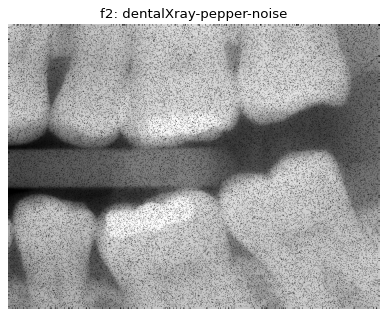

In [ ]:
f2 = plt.imread(os.path.join(imgpath, 'dentalXray-pepper-noise.tif'))
print('shape:', f2.shape, '| dtype:', f2.dtype, '| min/max:', f2.min(), f2.max())

# 계산은 실수형(float64)으로 하고, 밝기 범위는 0~255로 맞춘다
g = f2.astype(np.float64)
if g.ndim == 3:                                     # RGB(A)로 읽힌 경우 한 채널만 사용
    g = g[..., 0]
if np.issubdtype(f2.dtype, np.integer) and f2.dtype != np.uint8:
    g = g * 255.0 / np.iinfo(f2.dtype).max          # 16bit 등
elif np.issubdtype(f2.dtype, np.floating) and g.max() <= 1.0:
    g = g * 255.0                                   # [0, 1] 실수형
M, N = g.shape

plt.figure(figsize=(6, 5))
plt.imshow(g, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.title('f2: dentalXray-pepper-noise')
plt.show()

## 1. 잡음 특성
Pepper 잡음은 각 화소가 확률 $P$로 0(검은 점)이 되는 impulse 잡음이다. 손상된 화소는 원래 밝기와 상관없이 0이 되고, 손상되지 않은 화소는 원래 값 그대로 남는다. 그래서 히스토그램에서는 0 위치에 정상 밝기 분포와 동떨어진 막대가 솟고, 그 막대가 전체에서 차지하는 비율이 잡음 밀도 $P$의 추정치가 된다.

pepper 값 = 0, pepper 화소 60,450개 / 전체 603,840개  →  잡음 밀도 P ≈ 10.01%
정상 화소 밝기: 평균 166.8, 표준편차 52.4, 범위 1~255


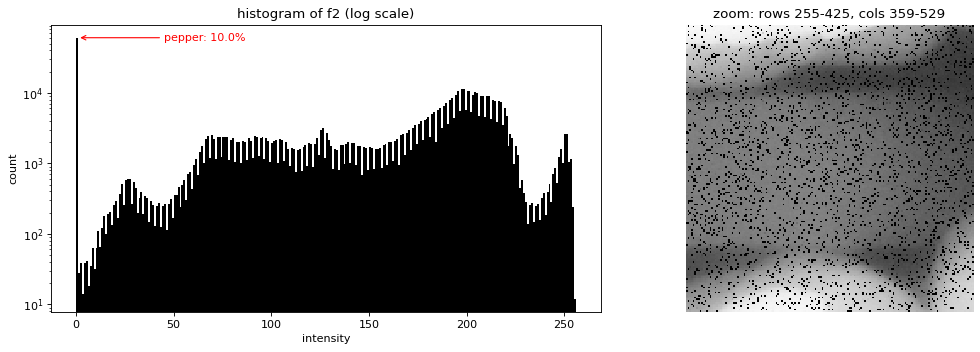

In [ ]:
pepper_val  = g.min()                 # pepper 값 (보통 0)
pepper_mask = (g == pepper_val)       # 손상된 화소
clean_mask  = ~pepper_mask            # 손상되지 않은 화소 (관측값 = 원래 값)
f_clean = g[clean_mask]
P_hat = pepper_mask.mean()
print(f'pepper 값 = {pepper_val:.0f}, pepper 화소 {pepper_mask.sum():,}개 / 전체 {g.size:,}개'
      f'  →  잡음 밀도 P ≈ {100*P_hat:.2f}%')
print(f'정상 화소 밝기: 평균 {f_clean.mean():.1f}, 표준편차 {f_clean.std():.1f}, '
      f'범위 {f_clean.min():.0f}~{f_clean.max():.0f}')

# 결과를 자세히 볼 확대 영역 (영상 중앙)
hz = min(M, N) // 4
r0, c0 = M // 2 - hz // 2, N // 2 - hz // 2
zoom = (slice(r0, r0 + hz), slice(c0, c0 + hz))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(g.ravel(), bins=256, range=(0, 256), color='k')
ax[0].set_yscale('log')
ax[0].annotate(f'pepper: {100*P_hat:.1f}%', xy=(pepper_val + 1, pepper_mask.sum()),
               xytext=(45, pepper_mask.sum()), color='r', va='center',
               arrowprops=dict(arrowstyle='->', color='r'))
ax[0].set_title('histogram of f2 (log scale)')
ax[0].set_xlabel('intensity'); ax[0].set_ylabel('count')
ax[1].imshow(g[zoom], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
ax[1].set_title(f'zoom: rows {r0}-{r0+hz}, cols {c0}-{c0+hz}')
ax[1].axis('off')
plt.tight_layout(); plt.show()

## 2. 필터 구현
$S_{xy}$ 는 $(x, y)$ 를 중심으로 한 $SS\times SS$ 창, $g$ 는 잡음 영상이다.

1. **Arithmetic mean**: $\hat f(x,y)=\dfrac{1}{SS^2}\displaystyle\sum_{(r,c)\in S_{xy}} g(r,c)$
2. **Median**: $\hat f(x,y)=\operatorname{median}\{\,g(r,c) : (r,c)\in S_{xy}\,\}$
3. **Adaptive local noise reduction**:
$$\hat f(x,y)=g(x,y)-\frac{\sigma_\eta^2}{\sigma_{S_{xy}}^2}\Big[g(x,y)-\bar z_{S_{xy}}\Big]$$
$\sigma_\eta^2$ 는 잡음 분산(영상 전체에 하나), $\bar z_{S_{xy}}$ 와 $\sigma_{S_{xy}}^2$ 는 창 안의 국소 평균과 국소 분산이다. 교재대로 $\sigma_\eta^2>\sigma_{S_{xy}}^2$ 이면 비율을 1로 제한해 음수나 과보정을 막는다. 실습코드에는 이 제한이 없어서 국소 분산이 0인 창에서는 0으로 나누게 된다.

**구현 방식.** 실습코드처럼 화소마다 창 $S_{xy}$ 를 잘라 평균, 중앙값, 분산을 구하는 정의 그대로다. 다만 이중 for문 대신 `sliding_window_view`로 모든 창을 한꺼번에 만들어 계산하고(메모리를 아끼려고 64행씩 나눠 처리), 테두리는 0으로 남기지 않고 대칭(symmetric) 패딩으로 처리해 영상 끝까지 복원한다. 바로 아래에서 실습코드식 for문 구현과 결과가 같은지 확인한다.

In [ ]:
def local_stat(img, SS, stat, chunk=64):
    '''각 화소를 중심으로 한 SS x SS 창 Sxy에 stat(np.mean, np.median, np.var, np.sum)을 적용한 영상'''
    ss = SS // 2
    fp = np.pad(img.astype(np.float64), ss, mode='symmetric')    # 테두리: 대칭 패딩
    H, W = img.shape
    out = np.empty((H, W))
    for r in range(0, H, chunk):                                 # chunk 행씩 나눠 처리
        r_end = min(r + chunk, H)
        Sxy = sliding_window_view(fp[r:r_end + 2*ss], (SS, SS))  # (행, 열, SS, SS): 화소별 창
        out[r:r_end] = stat(Sxy.reshape(r_end - r, W, SS*SS), axis=-1)
    return out


def arithmetic_mean_filter(g, SS=3):
    return local_stat(g, SS, np.mean)


def median_filter(g, SS=3):
    return local_stat(g, SS, np.median)


def adaptive_local_noise_reduction(g, SS=7, var_eta=None):
    '''반환: (복원 영상, 비율 k = min(var_eta / var_L, 1))'''
    g = g.astype(np.float64)
    m_L   = local_stat(g, SS, np.mean)          # 국소 평균
    var_L = local_stat(g, SS, np.var)           # 국소 분산
    if var_eta is None:                         # 잡음 분산을 모르면 국소 분산의 평균으로 대신한다
        var_eta = var_L.mean()
    k = np.ones_like(var_L)                     # var_L = 0 (완전히 평탄한 창) → 국소 평균
    nz = var_L > 0
    k[nz] = np.minimum(var_eta / var_L[nz], 1.0)    # var_eta > var_L 이면 비율 = 1
    return g - k * (g - m_L), k

In [ ]:
def filters_by_loop(img, SS, var_eta):
    ss = SS // 2
    fp = np.pad(img.astype(np.float64), ss, mode='symmetric')
    r_mean, r_median, r_amean = (np.zeros(img.shape) for _ in range(3))
    for x in range(img.shape[0]):
        for y in range(img.shape[1]):
            Sxy = fp[x:x+SS, y:y+SS]
            r_mean[x, y]   = np.mean(Sxy)
            r_median[x, y] = np.median(Sxy)
            var_S = np.std(Sxy)**2
            ratio = 1.0 if var_S == 0 else min(var_eta / var_S, 1.0)
            r_amean[x, y]  = img[x, y] - ratio * (img[x, y] - np.mean(Sxy))
    return r_mean, r_median, r_amean

test = g[zoom][:64, :64]
for SS in (3, 5, 7):
    lm, lmed, la = filters_by_loop(test, SS, var_eta=1000.0)
    same = (np.allclose(lm,   arithmetic_mean_filter(test, SS)) and
            np.allclose(lmed, median_filter(test, SS)) and
            np.allclose(la,   adaptive_local_noise_reduction(test, SS, var_eta=1000.0)[0]))

## 3. Arithmetic Mean Filter
창 크기 3×3, 5×5, 7×7을 비교한다. 윗줄은 전체 영상, 아랫줄은 빨간 상자 부분을 확대한 것이다.

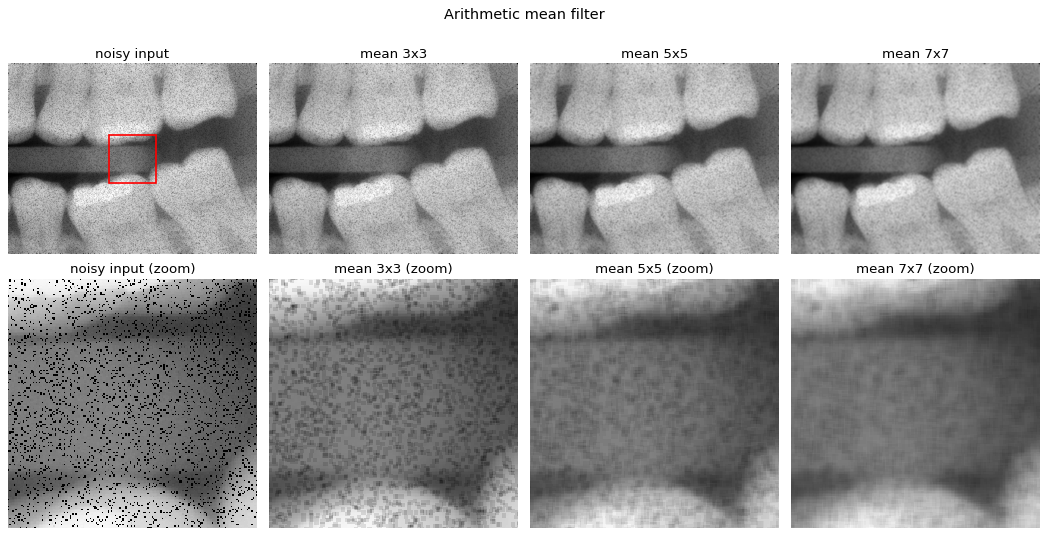

In [ ]:
sizes = [3, 5, 7]

def show_row(results, titles, suptitle, zoom_only=False):
    '''윗줄: 전체 영상, 아랫줄: 확대 영역 (첫 열은 잡음 영상). zoom_only=True면 확대 영역만'''
    imgs, names = [g] + list(results), ['noisy input'] + list(titles)
    nrow = 1 if zoom_only else 2
    fig, ax = plt.subplots(nrow, len(imgs), figsize=(3.3 * len(imgs), 3.4 * nrow),
                           squeeze=False)
    for i, (im, name) in enumerate(zip(imgs, names)):
        if not zoom_only:
            ax[0, i].imshow(im, cmap='gray', vmin=0, vmax=255)
            ax[0, i].set_title(name); ax[0, i].axis('off')
        ax[-1, i].imshow(im[zoom], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        ax[-1, i].set_title(name + ' (zoom)'); ax[-1, i].axis('off')
    if not zoom_only:
        ax[0, 0].add_patch(plt.Rectangle((c0, r0), hz, hz, fill=False, ec='r', lw=1.5))
    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout(); plt.show()

r_mean = {SS: arithmetic_mean_filter(g, SS) for SS in sizes}
show_row([r_mean[SS] for SS in sizes], [f'mean {SS}x{SS}' for SS in sizes], 'Arithmetic mean filter')

**관찰**
- pepper 점이 없어지지 않고 주변으로 번져 얼룩으로 남는다. 창이 커지면 얼룩은 옅어지지만 치아 경계(법랑질, 치근 윤곽) 같은 구조도 함께 흐려진다.
- 영상 전체가 어두워진다. pepper는 값을 항상 0 쪽으로만 바꾸는, 평균이 0이 아닌 잡음이다. 그래서 창 안 평균의 기대값이 $(1-P)\,f$ 가 되어 원래 밝기보다 약 $P$ 비율만큼 낮아진다(6장 표의 밝기 편향).
- 평균 필터는 평균이 0인 가우시안류 잡음을 줄이는 데 맞는 필터다. 극단값 하나가 평균 전체를 끌어내리므로 pepper 잡음에는 맞지 않는다.

## 4. Median Filter
창 안의 값을 정렬해 가운데 값을 고른다. 창 안 pepper가 절반보다 적으면 0은 정렬의 한쪽 끝으로 밀려나 결과에 영향을 주지 않는다. 반대로 창의 절반 이상이 pepper이면 결과도 0이 된다. 따라서 잡음 밀도가 $P$일 때 출력에 남는 pepper 비율은 이항분포로 예측할 수 있다.
$$\Pr\left[X \ge \tfrac{n+1}{2}\right],\qquad X\sim\mathrm{Binomial}(n=SS^2,\ P)$$

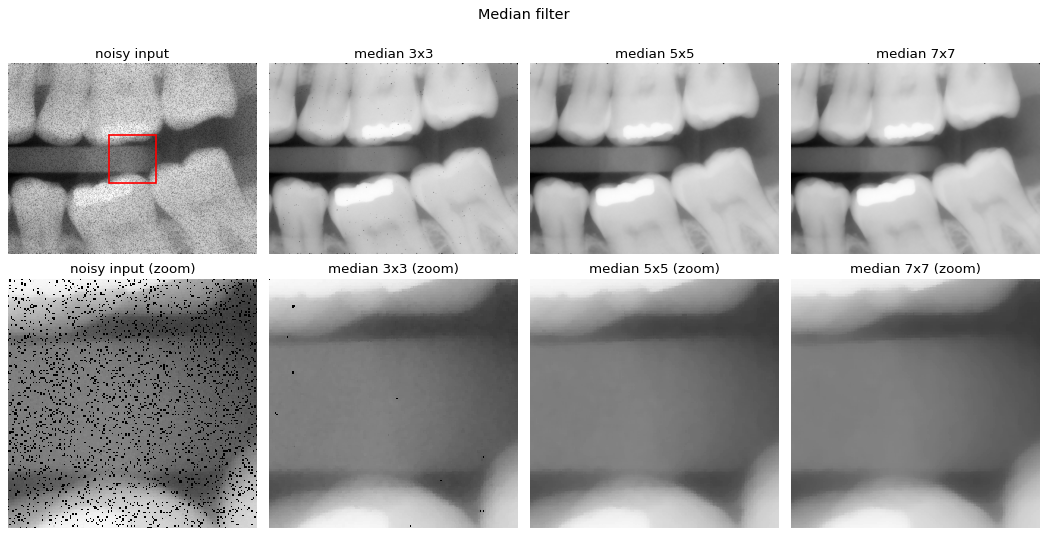

출력에 남은 pepper 비율 (실측 vs 이항분포 예측)
  3x3: 실측 0.1845%   예측 0.0895%
  5x5: 실측 0.0603%   예측 0.0000%
  7x7: 실측 0.0510%   예측 0.0000%

→ 비교에 쓸 창 크기 SSc = 5x5


In [ ]:
r_median = {SS: median_filter(g, SS) for SS in sizes}
show_row([r_median[SS] for SS in sizes], [f'median {SS}x{SS}' for SS in sizes], 'Median filter')

print('출력에 남은 pepper 비율 (실측 vs 이항분포 예측)')
resid = {}
for SS in sizes:
    n = SS * SS
    resid[SS] = np.mean(r_median[SS] == pepper_val)
    print(f'  {SS}x{SS}: 실측 {100*resid[SS]:.4f}%   예측 {100*binom.sf(n // 2, n, P_hat):.4f}%')

# 6장 비교에 쓸 창 크기: 남은 pepper가 0.1% 미만이 되는 가장 작은 창
SSc = next((SS for SS in sizes if resid[SS] < 1e-3), sizes[-1])
print(f'\n→ 비교에 쓸 창 크기 SSc = {SSc}x{SSc}')

**관찰**
- 같은 창 크기에서 평균 필터보다 pepper가 훨씬 깨끗하게 사라지고 치아 경계도 선명하게 유지된다. 중앙값은 창 안에 실제로 있던 값 중 하나라서, 경계 양쪽 값을 섞어 중간 밝기를 만들지 않기 때문이다.
- 3×3에서는 창의 절반 이상이 우연히 pepper인 곳에 점이 조금 남고, 5×5부터는 눈에 띄는 점이 없다.
- 다만 0으로 남은 화소의 실측 비율은 예측보다 크고, 5×5와 7×7에서도 약 0.05%가 남는다. $P\approx10\%$ 에서 5×5 창의 절반(13개) 이상이 우연히 pepper일 확률은 사실상 0이므로, 이 화소들은 pepper가 아니라 **원영상에서 처음부터 0이었던 검은 화소**다(정상 화소의 최솟값이 1일 만큼 원영상에 아주 어두운 부분이 있다). 1장에서 0인 화소를 모두 pepper로 셌기 때문에 이 화소들이 '남은 pepper'로 집계되었고, 잡음 밀도 $P$도 그만큼 약간 크게 잡혔다. 같은 이유로 6장의 근사 기준영상은 이 화소들을 주변 밝기로 채우므로, 이 화소를 0으로 유지하는 median의 PSNR은 실제보다 낮게 계산된다.
- 창이 커질수록 가는 구조와 모서리가 둥글게 뭉개진다. 그래서 pepper가 거의 남지 않는 가장 작은 창(위의 SSc)을 고르는 것이 좋다.

## 5. Adaptive Local Noise Reduction
비율을 $k=\min\left(\sigma_\eta^2/\sigma_{S_{xy}}^2,\ 1\right)$ 로 두면 식은 다음과 같다.
$$\hat f(x,y)=(1-k)\,g(x,y)+k\,\bar z_{S_{xy}}$$
즉 **원래 화소값과 국소 평균의 가중평균**이다. 국소 분산이 잡음 분산 정도인 평탄한 영역에서는 $k\to1$ 이라 평균 필터처럼 동작하고, 경계처럼 국소 분산이 큰 곳에서는 $k\to0$ 이라 원래 값을 유지한다.

**잡음 분산 $\sigma_\eta^2$ 추정.** 실습코드에서는 가우시안 잡음을 직접 더했기 때문에 잡음 크기를 알고 `std_eta = 16` 처럼 값을 정해 줄 수 있었지만, 여기서는 영상에서 추정해야 한다. pepper 잡음을 덧셈 잡음 $\eta=g-f$ 로 보면, 확률 $P$로 $\eta=-f$ 이고 나머지는 $\eta=0$ 이다. 따라서
$$\sigma_\eta^2=E[\eta^2]-(E[\eta])^2=P\,E[f^2]-P^2\,(E[f])^2$$
이고, $P$는 1장의 pepper 비율로, $E[f]$와 $E[f^2]$는 손상되지 않은 화소로 구한다.

추정 잡음 분산 σ_η² = 2781.2  (σ_η = 52.7)


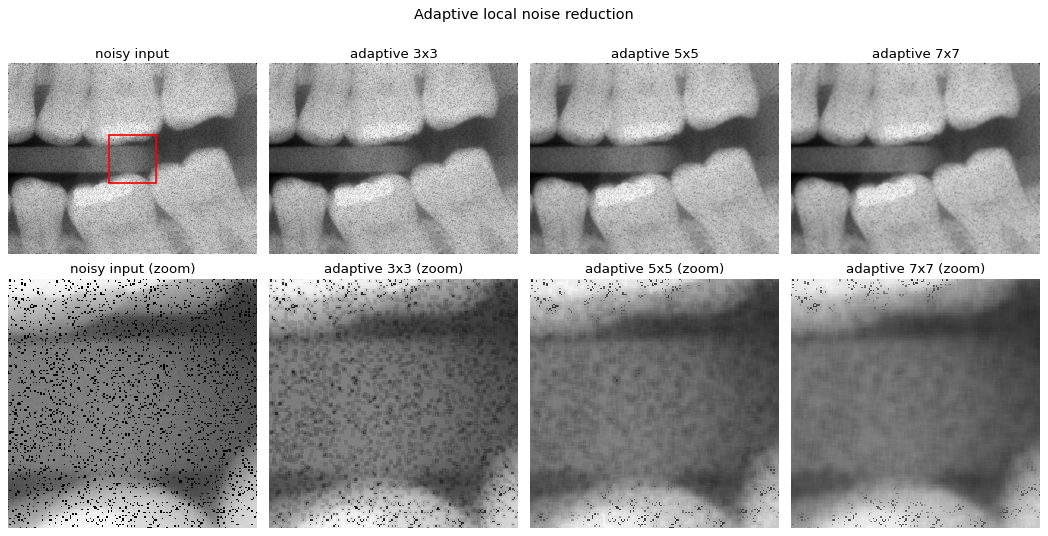

In [ ]:
var_eta = P_hat * np.mean(f_clean**2) - (P_hat * f_clean.mean())**2
print(f'추정 잡음 분산 σ_η² = {var_eta:.1f}  (σ_η = {np.sqrt(var_eta):.1f})')

r_alnr, k_alnr = {}, {}
for SS in sizes:
    r_alnr[SS], k_alnr[SS] = adaptive_local_noise_reduction(g, SS, var_eta)
show_row([r_alnr[SS] for SS in sizes], [f'adaptive {SS}x{SS}' for SS in sizes],
         'Adaptive local noise reduction')

아래 왼쪽은 화소마다의 비율 $k$ 이다($k=1$: 평균 필터와 같음, $k\to0$: 원래 값 유지). 오른쪽은 밝기(pepper를 뺀 median 결과)에 따라 $k$ 의 평균을 낸 것이다.

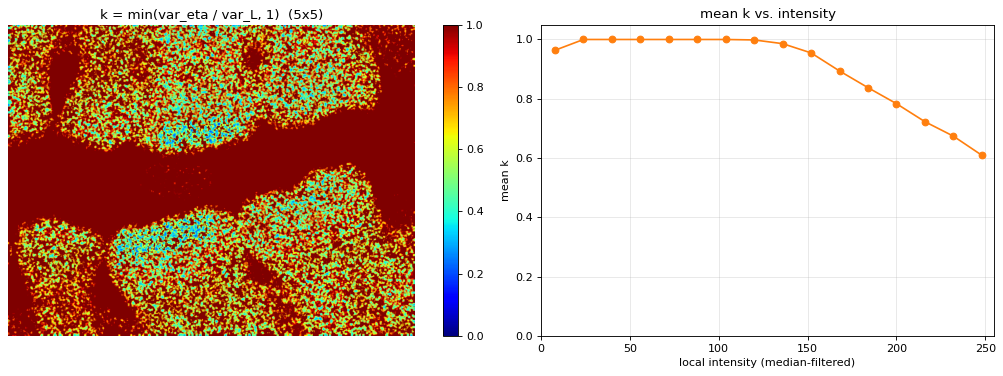

k = 1 (평균 필터와 같음)인 화소 비율: 56.8%


In [ ]:
k = k_alnr[SSc]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
im = ax[0].imshow(k, cmap='jet', vmin=0, vmax=1)
ax[0].set_title(f'k = min(var_eta / var_L, 1)  ({SSc}x{SSc})'); ax[0].axis('off')
plt.colorbar(im, ax=ax[0], fraction=0.046)

level = r_median[SSc]                         # pepper를 뺀 밝기 추정
edges = np.arange(0, 256 + 16, 16)
centers, k_mean = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (level >= lo) & (level < hi)
    if sel.sum() > 200:
        centers.append((lo + hi) / 2); k_mean.append(k[sel].mean())
ax[1].plot(centers, k_mean, 'o-', color='tab:orange')
ax[1].set_ylim(0, 1.05); ax[1].set_xlim(0, 255)
ax[1].set_xlabel('local intensity (median-filtered)'); ax[1].set_ylabel('mean k')
ax[1].set_title('mean k vs. intensity'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'k = 1 (평균 필터와 같음)인 화소 비율: {100*np.mean(k >= 1):.1f}%')

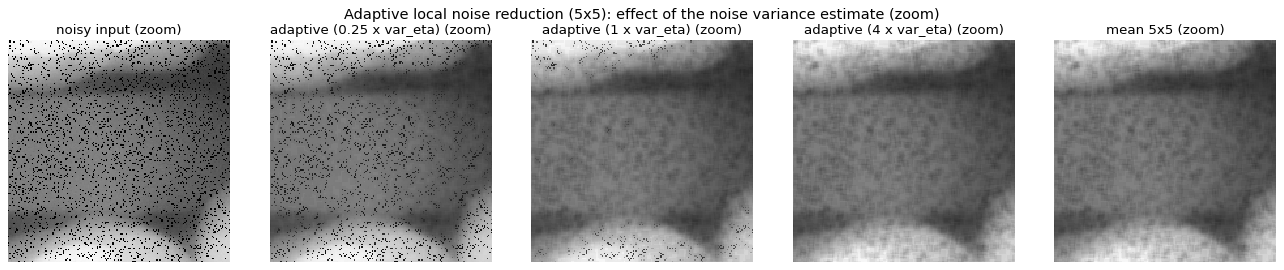

In [ ]:
# σ_η² 를 잘못 잡으면? 작게 잡으면 입력에 가깝고(k→0), 크게 잡으면 평균 필터와 같아진다(k=1)
scales = [0.25, 1, 4]
sweep = [adaptive_local_noise_reduction(g, SSc, s * var_eta)[0] for s in scales]
show_row(sweep + [r_mean[SSc]],
         [f'adaptive ({s} x var_eta)' for s in scales] + [f'mean {SSc}x{SSc}'],
         f'Adaptive local noise reduction ({SSc}x{SSc}): effect of the noise variance estimate (zoom)',
         zoom_only=True)

**관찰**
- 어두운 영역(위아래 치아 사이 등)에서는 평균 필터 결과와 거의 같고, 밝은 치아 안에서는 pepper 점이 평균 필터보다 진하게 남는다.
- 원인은 위의 $k$ 그림에 보인다. pepper 잡음의 국소 분산은 평탄한 영역에서 약 $P(1-P)f^2$ 으로 **밝기의 제곱에 비례**한다. 그래서 밝은 영역은 국소 분산이 전역 추정치 $\sigma_\eta^2$ 보다 커서 $k<1$ (원래 값 유지), 어두운 영역은 $k=1$ (평균 필터)이 된다. 이 필터가 가정하는 '밝기와 무관하고 평균이 0인 덧셈 잡음'과 맞지 않는 것이다.
- pepper 화소($g=0$)의 출력은 $k\,\bar z_{S_{xy}} \le \bar z_{S_{xy}}$ 이다. 따라서 $\sigma_\eta^2$ 를 어떻게 잡아도 pepper 화소를 평균 필터보다 밝게 복원할 수 없고, $\sigma_\eta^2$ 를 키우면 결국 평균 필터와 같아진다(위 그림의 마지막 두 칸).
- 이 필터는 실습코드의 가우시안 잡음처럼 덧셈 잡음일 때 경계를 지키면서 평활화하는 장점이 있지만, pepper 화소를 복원하는 능력은 평균 필터를 넘을 수 없다.

## 6. 세 필터 비교
4장에서 정한 같은 창 크기(SSc)에서 세 필터를 비교한다.

**정량 지표.** 깨끗한 원영상이 없으므로 다음과 같이 평가한다.
- **정상 화소 MAE**: pepper가 아닌 화소는 관측값이 곧 원래 값이다. 이 화소들에서 $|\hat f-g|$ 의 평균은 필터가 멀쩡한 화소를 얼마나 바꿨는지(흐림, 밝기 변화)를 정확히 보여 준다. 작을수록 좋다.
- **밝기 편향**: 정상 화소에서 $\hat f-g$ 의 평균이다. 음수면 영상이 어두워졌다는 뜻이다.
- **PSNR (근사 기준영상)**: 정상 화소는 관측값, pepper 화소는 주변 5×5 안의 정상 화소 평균으로 채운 영상을 기준으로 계산한다. pepper 제거와 정상 화소 보존을 함께 반영한다. 기준영상이 근사이므로 필터끼리의 상대 비교로만 본다.

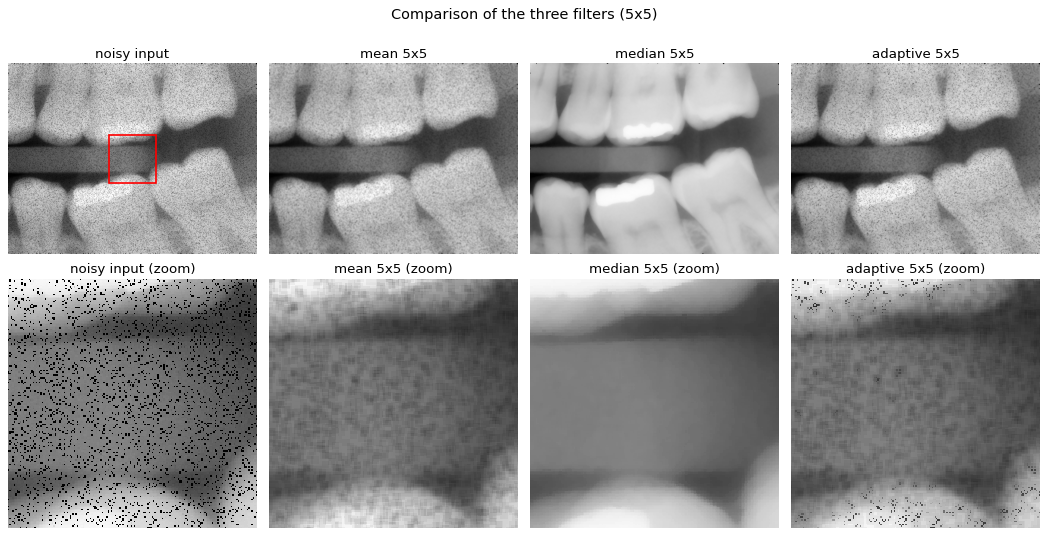

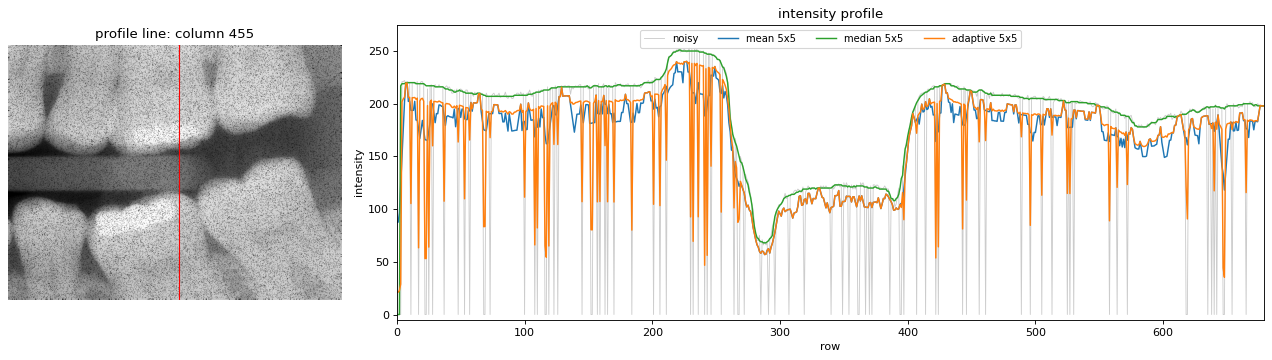

In [ ]:
results = {'mean': r_mean[SSc], 'median': r_median[SSc], 'adaptive': r_alnr[SSc]}
show_row(list(results.values()), [f'{name} {SSc}x{SSc}' for name in results],
         f'Comparison of the three filters ({SSc}x{SSc})')

# 세로 단면(profile): 가운데 1/3 열 중 경계가 가장 뚜렷한 열을 자동으로 고른다
cols = np.arange(N // 3, 2 * N // 3)
col = cols[np.argmax(np.abs(np.diff(r_median[SSc][:, cols], axis=0)).sum(axis=0))]

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1, 2.6]})
ax[0].imshow(g, cmap='gray', vmin=0, vmax=255)
ax[0].axvline(col, color='r', lw=1)
ax[0].set_title(f'profile line: column {col}'); ax[0].axis('off')
ax[1].plot(g[:, col], color='0.8', lw=0.8, label='noisy')
for (name, res), c in zip(results.items(), ['tab:blue', 'tab:green', 'tab:orange']):
    ax[1].plot(res[:, col], color=c, lw=1.3, label=f'{name} {SSc}x{SSc}')
ax[1].set_xlim(0, M - 1); ax[1].set_ylim(-5, 275)
ax[1].set_xlabel('row'); ax[1].set_ylabel('intensity'); ax[1].set_title('intensity profile')
ax[1].legend(loc='upper center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

In [ ]:
# 근사 기준영상: 정상 화소는 관측값 그대로, pepper 화소는 주변 5x5 안의 정상 화소 평균
num = local_stat(np.where(clean_mask, g, 0.0), 5, np.sum)
cnt = local_stat(clean_mask.astype(np.float64), 5, np.sum)
fill = np.divide(num, cnt, out=np.full_like(num, f_clean.mean()), where=cnt > 0)
f_ref = np.where(pepper_mask, fill, g)

def psnr(x, ref):
    return 10 * np.log10(255.0**2 / np.mean((x - ref)**2))

rows = [{'필터': 'noisy input', '창 크기': '-', 'PSNR [dB]': psnr(g, f_ref),
         '정상 화소 MAE': 0.0, '밝기 편향': 0.0}]
for name, res in [('arithmetic mean', r_mean), ('median', r_median), ('adaptive local', r_alnr)]:
    for SS in sizes:
        d = (res[SS] - g)[clean_mask]
        rows.append({'필터': name, '창 크기': f'{SS}x{SS}', 'PSNR [dB]': psnr(res[SS], f_ref),
                     '정상 화소 MAE': np.abs(d).mean(), '밝기 편향': d.mean()})
table = pd.DataFrame(rows).round(2)
table

,필터,창 크기,PSNR [dB],정상 화소 MAE,밝기 편향
0,noisy input,-,13.28,0.00,0.00
1,arithmetic mean,3x3,20.13,15.30,-14.74
2,arithmetic mean,5x5,21.78,16.12,-15.94
3,arithmetic mean,7x7,22.37,16.38,-16.29
4,median,3x3,31.04,1.28,-0.29
5,median,5x5,36.79,1.39,-0.29
6,median,7x7,37.67,1.51,-0.38
7,adaptive local,3x3,17.35,9.66,-9.09
8,adaptive local,5x5,18.99,11.80,-11.62
9,adaptive local,7x7,19.79,12.59,-12.50


In [ ]:
t = table.iloc[1:]
best = t.loc[t['PSNR [dB]'].idxmax()]
print(f"PSNR이 가장 높은 결과: {best['필터']} {best['창 크기']} "
      f"({best['PSNR [dB]']:.2f} dB, 입력 영상 {table.loc[0, 'PSNR [dB]']:.2f} dB)")

at = t[t['창 크기'] == f'{SSc}x{SSc}'].set_index('필터')
print(f'\n같은 창 크기 {SSc}x{SSc}에서')
for name in at.index:
    print(f"  {name:16s} PSNR {at.loc[name, 'PSNR [dB]']:6.2f} dB | "
          f"정상 화소 MAE {at.loc[name, '정상 화소 MAE']:6.2f} | 밝기 편향 {at.loc[name, '밝기 편향']:7.2f}")

n = SSc * SSc
print(f'\n평균 필터 밝기 편향의 이론값 ≈ -P·(n-1)/n·E[f] = {-P_hat * (n - 1) / n * f_clean.mean():.2f}'
      f'  (n = {SSc}x{SSc}, 위 표의 실측값과 비교)')

PSNR이 가장 높은 결과: median 7x7 (37.67 dB, 입력 영상 13.28 dB)

같은 창 크기 5x5에서
  arithmetic mean  PSNR  21.78 dB | 정상 화소 MAE  16.12 | 밝기 편향  -15.94
  median           PSNR  36.79 dB | 정상 화소 MAE   1.39 | 밝기 편향   -0.29
  adaptive local   PSNR  18.99 dB | 정상 화소 MAE  11.80 | 밝기 편향  -11.62

평균 필터 밝기 편향의 이론값 ≈ -P·(n-1)/n·E[f] = -16.03  (n = 5x5, 위 표의 실측값과 비교)


## 7. 결론
1. **Pepper 잡음에는 median 필터가 가장 적합하다.** 정렬해서 가운데 값을 고르는 순서통계 필터라 창 안의 극단값(0)이 결과에 섞이지 않고, 창에 실제로 있던 값을 내보내므로 경계와 밝기가 보존된다. 6장의 같은 5×5 창 비교에서도 pepper가 가장 깨끗하게 사라지고, PSNR은 median 36.8 dB, mean 21.8 dB, adaptive 19.0 dB, 밝기 편향은 각각 −0.3, −15.9, −11.6이다. 창 크기는 5×5로 정했다. 3×3은 pepper가 일부 남고, 7×7은 PSNR이 0.9 dB 높지만 정상 화소 MAE가 커져(1.39 → 1.51) 경계가 더 흐려진다.
2. **Arithmetic mean 필터**는 pepper를 주변으로 퍼뜨려 얼룩을 남기고, 영상을 약 $P\times$(밝기)만큼 어둡게 하며, 경계를 흐린다. 5×5에서 밝기 편향의 실측값(−15.9)이 이론값(−16.0)과 거의 같다.
3. **Adaptive local noise reduction 필터**는 원래 값과 국소 평균의 가중평균이라 pepper 화소를 평균 필터보다 밝게 복원할 수 없다. 또 pepper 잡음의 분산은 밝기에 따라 달라서, 전역 $\sigma_\eta^2$ 하나로는 밝은 치아 영역에 잡음이 남는다. 실습코드의 가우시안 잡음처럼 덧셈 잡음이고, 평균이 0이며, 밝기와 무관한 잡음일 때 장점이 살아나는 필터다.
4. 더 개선하려면 pepper로 판단된 화소만 바꾸는 **adaptive median filter**나, $Q>0$ 으로 두어 pepper를 제거하는 **contraharmonic mean filter**를 쓸 수 있다.

## 8. 결과 저장
복원 결과를 `f2_r` 로 시각화하고 그림 파일로 저장한다. 가장 좋은 결과인 median 필터(SSc) 결과를 `f2_r` 로 쓰고, 세 필터의 결과를 저장한다.

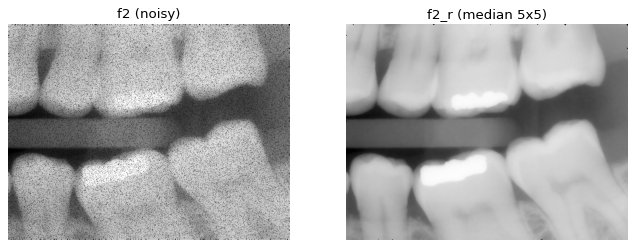

저장한 파일: ['denoised-dentalXray-adaptive-5x5.png', 'denoised-dentalXray-mean-5x5.png', 'denoised-dentalXray-median-5x5.png', 'denoised-dentalXray.png']


In [ ]:
f2_r = r_median[SSc]    # denoised f2

plt.figure(figsize=(10, 4.5))
plt.subplot(121); plt.imshow(g, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.title('f2 (noisy)')
plt.subplot(122); plt.imshow(f2_r, cmap='gray', vmin=0, vmax=255); plt.axis('off')
plt.title(f'f2_r (median {SSc}x{SSc})')
plt.show()

plt.imsave('denoised-dentalXray.png', f2_r, cmap='gray', vmin=0, vmax=255)
for name, res in [('mean', r_mean), ('median', r_median), ('adaptive', r_alnr)]:
    plt.imsave(f'denoised-dentalXray-{name}-{SSc}x{SSc}.png', res[SSc], cmap='gray', vmin=0, vmax=255)
print('저장한 파일:', sorted(fn for fn in os.listdir('.') if fn.startswith('denoised-dentalXray')))